In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
from tqdm.auto import tqdm

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dev = torch.device("mps")

BOX_SIZE = 10.0
V_FISH = 3.5
RADIUS = 0.3
POPULATION = 1000
NUM_NEURONS = 64

In [3]:
import warnings
warnings.filterwarnings('ignore')

rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})
rc('text', usetex=True)
plt.rcParams['axes.linewidth'] = 1
plt.rcParams['text.latex.preamble'] = r'\usepackage{braket}'
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsfonts}'

In [4]:
def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

In [5]:
class Actor(nn.Module):
    def __init__(self):
        super(Actor, self).__init__()
        # The state is (x0, y0, z0), though we transform z0 -> T = sqrt(2*z0 / g)
        self.net = nn.Sequential(nn.Linear(3, NUM_NEURONS), nn.ReLU(), nn.Linear(NUM_NEURONS, NUM_NEURONS), nn.ReLU())

        self.wait_out = nn.Linear(NUM_NEURONS, 1) # Wait fraction (between 0 and 1)
        self.phi_out = nn.Linear(NUM_NEURONS, 1)  # Heading angle (between -pi and pi)

    def forward(self, state):
        features = self.net(state)

        wait_frac = torch.sigmoid(self.wait_out(features)) # Sigmoid activation function
        phi = torch.tanh(self.phi_out(features)) * np.pi # Tanh activation function

        return torch.cat([wait_frac, phi], dim=-1) # Control vector

class Critic(nn.Module):
    def __init__(self):
        super(Critic, self).__init__()
        
        self.net = nn.Sequential(nn.Linear(5, NUM_NEURONS), nn.ReLU(), nn.Linear(NUM_NEURONS, NUM_NEURONS), nn.ReLU(), nn.Linear(NUM_NEURONS, 1))

    def forward(self, state, action):
        return self.net(torch.cat([state, action], dim=-1))

In [6]:
def generate_batch(batch_size):
    fish_pos = BOX_SIZE*torch.rand((batch_size, 2), device=dev)
    fruit_pos = BOX_SIZE*torch.rand((batch_size, 2), device=dev)
    T_impact = 5.0*torch.rand((batch_size, 1), device=dev) + 1.0

    relative_pos = fruit_pos - fish_pos
    state = torch.cat([relative_pos, T_impact], dim=-1)
    return state, fish_pos, fruit_pos

def compute_reward(state, action, fish_pos, fruit_pos):
    T_impact = state[:, 2:3]
    wait_frac = action[:, 0:1]
    phi = action[:, 1:2]

    wait_time = wait_frac*T_impact
    swim_time = T_impact - wait_time
    swim_distance = swim_time*V_FISH

    move_x = swim_distance*torch.cos(phi)
    move_y = swim_distance*torch.sin(phi)

    final_pos = torch.cat([torch.clamp(fish_pos[:, 0:1] + move_x, 0, BOX_SIZE), torch.clamp(fish_pos[:, 1:2] + move_y, 0, BOX_SIZE)], dim=-1)
    distances = torch.norm(final_pos - fruit_pos, dim=-1, keepdim=True)
    
    return -distances, final_pos

def optimal_policy(state):
    dx = state[:, 0:1]
    dy = state[:, 1:2]
    T_impact = state[:, 2:3]

    relative_distance = torch.norm(state[:, 0:2], dim=-1, keepdim=True)
    phi_opt = torch.atan2(dy, dx)

    swim_time_needed = relative_distance/V_FISH
    wait_time_opt = torch.clamp(T_impact - swim_time_needed, min=0.0)
    wait_frac_opt = wait_time_opt/T_impact

    return torch.cat([wait_frac_opt, phi_opt], dim=-1)

In [7]:
actor = Actor().to(dev)
critic = Critic().to(dev)

untrained_actor = Actor().to(dev)
untrained_actor.eval()

actor_opt = optim.Adam(actor.parameters(), lr=1e-3)
critic_opt = optim.Adam(critic.parameters(), lr=2e-3)

NUM_EPISODES = 2500
NOISE_STD_START = 1.00
NOISE_STD_END = 0.05

reward_history = []
error_history = []

fixed_test_states, _, _ = generate_batch(100)
opt_actions_fixed = optimal_policy(fixed_test_states)
opt_wait_fixed = opt_actions_fixed[:, 0].cpu().numpy()
opt_phi_fixed = opt_actions_fixed[:, 1].cpu().numpy()

history_RL_wait = []
history_RL_phi = []
history_episodes_tracked = []
all_trajectories = []

test_states_tracking, _, _ = generate_batch(1000)
opt_actions_tracking = optimal_policy(test_states_tracking).cpu().numpy()
tracking_history = []

for ep in tqdm(range(NUM_EPISODES), desc="Training Neural Network"):
    if ep%500 == 0:
        with torch.no_grad():
            current_actions = actor(test_states_tracking).cpu().numpy()
        tracking_history.append((ep, current_actions))

    noise_std = NOISE_STD_START - (NOISE_STD_START - NOISE_STD_END) * (ep / NUM_EPISODES)
    state, fish_pos, fruit_pos = generate_batch(POPULATION)

    with torch.no_grad():
        action_noisy = actor(state) + torch.randn_like(actor(state))*noise_std

        action_noisy[:, 0:1] = torch.clamp(action_noisy[:, 0:1], 0.0, 1.0)
        action_noisy[:, 1:2] = torch.clamp(action_noisy[:, 1:2], -np.pi, np.pi)

        rewards, final_pos = compute_reward(state, action_noisy, fish_pos, fruit_pos)

        for i in range(5):
            start_p = fish_pos[i].cpu().numpy()
            end_p = final_pos[i].cpu().numpy()
            all_trajectories.append(np.vstack((start_p, end_p)))

    critic_pred = critic(state, action_noisy)
    critic_loss = F.mse_loss(critic_pred, rewards)

    critic_opt.zero_grad()
    critic_loss.backward()
    critic_opt.step()

    best_actions = actor(state)
    actor_loss = -critic(state, best_actions).mean()

    actor_opt.zero_grad()
    actor_loss.backward()
    actor_opt.step()

    mean_error = -rewards.mean().item()
    reward_history.append(rewards.mean().item())
    error_history.append(mean_error)

    if ep%25 == 0:
        with torch.no_grad():
            tracked_actions = actor(fixed_test_states)
            history_RL_wait.append(tracked_actions[:, 0].cpu().numpy())
            history_RL_phi.append(tracked_actions[:, 1].cpu().numpy())
            history_episodes_tracked.append(ep)


with torch.no_grad():
    final_actions = actor(test_states_tracking).cpu().numpy()
tracking_history.append((NUM_EPISODES, final_actions))

print(f"Final average error: {np.mean(error_history[-50:]):.4f}")

Training Neural Network: 100%|██████████| 2500/2500 [00:14<00:00, 177.87it/s]

Final average error: 1.0410


In [8]:
actor.eval()
test_states, _, _ = generate_batch(POPULATION)

with torch.no_grad():
    RL_actions = actor(test_states)
    opt_actions = optimal_policy(test_states)

RL_wait = RL_actions[:, 0].cpu().numpy()
RL_phi = RL_actions[:, 1].cpu().numpy()
opt_wait = opt_actions[:, 0].cpu().numpy()
opt_phi = opt_actions[:, 1].cpu().numpy()

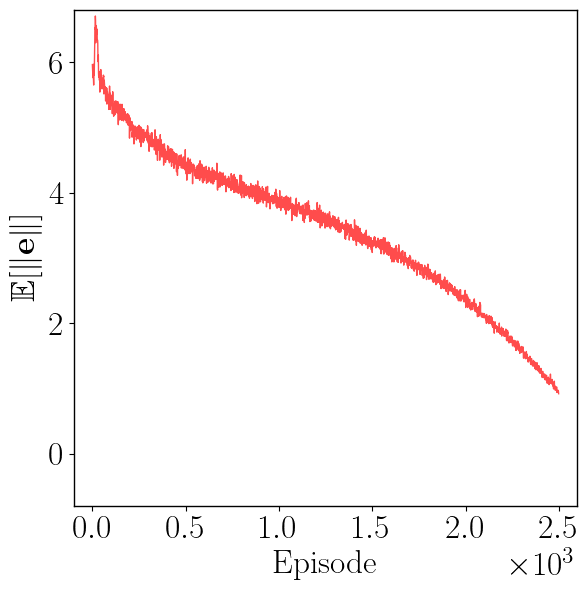

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(error_history, color='red', alpha=0.7, linewidth=1)
ax.set_xlabel('Episode', fontsize=24)
ax.set_ylabel(r'$\mathbb{E}[\|\mathbf{e}\|]$', fontsize=24)
ax.grid(False)
ax.set_xlim(-100, 2600)
ax.set_ylim(-0.80, 6.80)
ax.set_xticks([0, 500, 1000, 1500, 2000, 2500])
ax.set_yticks([0, 2, 4, 6])
ax.ticklabel_format(style='sci', axis='x', scilimits=(0,0), useMathText=True)
ax.xaxis.get_offset_text().set_fontsize(24)
ax.tick_params(axis='both', which='major', labelsize=24)

plt.tight_layout()
plt.savefig('RL_error.pdf', format='pdf', dpi=600)
plt.show()

In [10]:
def calculate_R2(X, Y):
    return np.corrcoef(X, Y)[0, 1]**2

In [11]:
def circular_r_squared(phi1, phi2):
    phi1, phi2 = np.asarray(phi1), np.asarray(phi2)
    
    mean_phi1, mean_phi2 = np.arctan2(np.sum(np.sin(phi1)), np.sum(np.cos(phi1))), np.arctan2(np.sum(np.sin(phi2)), np.sum(np.cos(phi2)))
    
    sin_diff1, sin_diff2 = np.sin(phi1 - mean_phi1), np.sin(phi2 - mean_phi2)
    
    numerator = np.sum(sin_diff1*sin_diff2)
    denominator = np.sqrt(np.sum(sin_diff1**2)*np.sum(sin_diff2**2))
        
    if denominator == 0.0: 
        return 0.0
    else:
        return (numerator/denominator)**2

In [12]:
def plot_R2(X, Y, data_type, ax, x_position=0.125, y_position=0.95):
    if data_type == 'Linear':
        R2 = calculate_R2(X, Y)
    elif data_type == 'Circular':
        R2 = circular_r_squared(X, Y)
    else:
        R2 = None
    
    text_str = f'$R^2 = {R2:.3f}$'

    ax.text(x_position, y_position, text_str, transform=ax.transAxes, fontsize=24, verticalalignment='top')

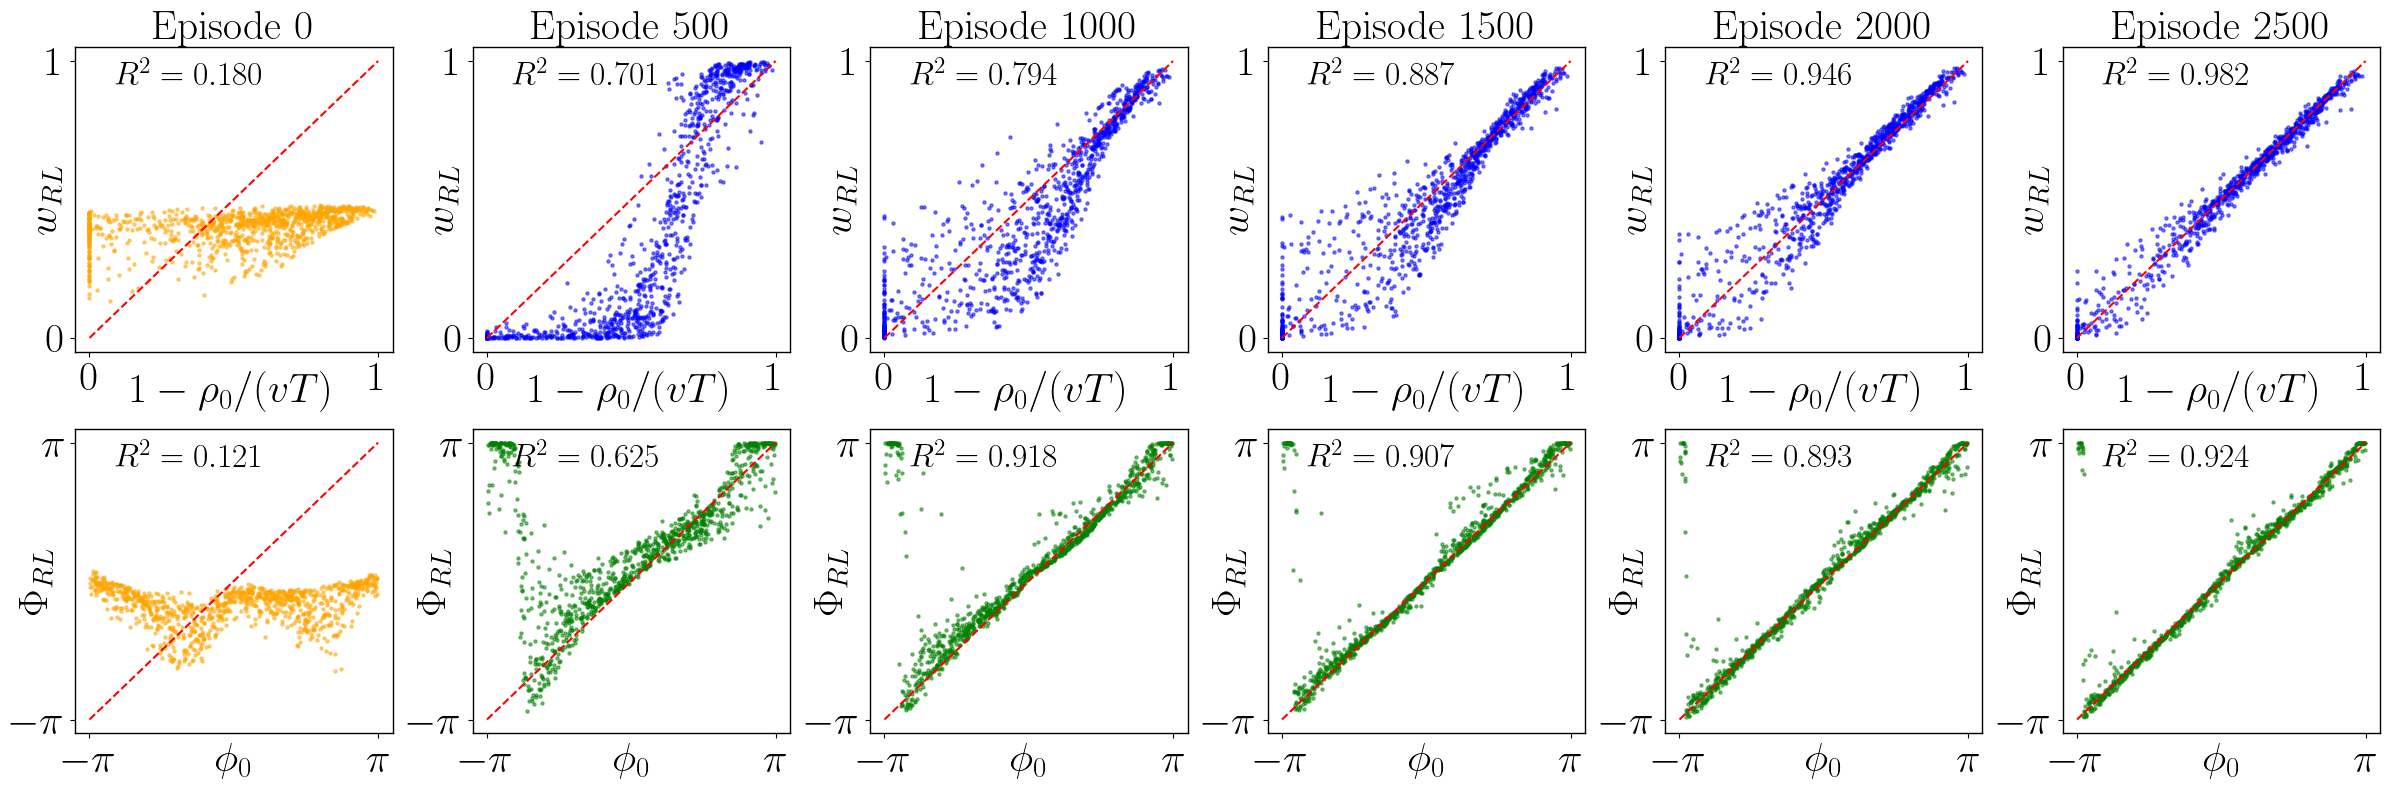

In [13]:
num_plots = len(tracking_history)
fig, axs = plt.subplots(2, num_plots, figsize=(4.0*num_plots, 8))

x_wait_opt = opt_actions_tracking[:, 0]
x_phi_opt = opt_actions_tracking[:, 1]

for idx, (ep, actions) in enumerate(tracking_history):
    y_wait_RL = actions[:, 0]
    y_phi_RL = actions[:, 1]
    
    axs[0, idx].scatter(x_wait_opt, y_wait_RL, color='orange' if ep == 0 else 'blue', alpha=0.5, s=5)
    axs[0, idx].set_title(f'Episode {ep}', fontsize=30)
    axs[0, idx].plot([0, 1], [0, 1], 'r--')
    axs[0, idx].set_xlabel(r'$1 - \rho_{0} / (v T)$', fontsize=30, labelpad=-20)
    axs[0, idx].set_ylabel(r'$w_{RL}$', fontsize=30, labelpad=-12.5)
    axs[0, idx].grid(False)
    axs[0, idx].set_xticks([0, 1])
    axs[0, idx].set_yticks([0, 1])
    axs[0, idx].tick_params(axis='both', which='major', labelsize=30)
    plot_R2(x_wait_opt, y_wait_RL, 'Linear', axs[0, idx])
    
    axs[1, idx].scatter(x_phi_opt, y_phi_RL, color='orange' if ep == 0 else 'green', alpha=0.5, s=5)
    axs[1, idx].plot([-np.pi, np.pi], [-np.pi, np.pi], 'r--')
    axs[1, idx].set_xlabel(r'$\phi_{0}$', fontsize=30, labelpad=-27.5)
    axs[1, idx].set_ylabel(r'$\Phi_{RL}$', fontsize=30, labelpad=-32.5)
    axs[1, idx].grid(False)
    axs[1, idx].set_xticks([-np.pi, np.pi])
    axs[1, idx].set_xticklabels([r'$-\pi$', r'$\pi$'])
    axs[1, idx].set_yticks([-np.pi, np.pi])
    axs[1, idx].set_yticklabels([r'$-\pi$', r'$\pi$'])
    axs[1, idx].tick_params(axis='both', which='major', labelsize=30)
    plot_R2(x_phi_opt, y_phi_RL, 'Circular', axs[1, idx])

plt.tight_layout()
plt.savefig('RL_training_plots.pdf', format='pdf', dpi=600)
plt.show()